A quadratic program (QP) has a quadratic objective and linear constraints. This lesson starts with
the simplest way to minimise a smooth function, gradient descent, then writes one QP in standard
form, checks that it is convex, and solves it three ways: by gradient descent (which ignores the
constraints), by a few interior-point steps (which does not), and by Gurobi.

$$\begin{aligned} \min\ z = x_1^2 + 4x_2^2 - 8x_1 - 16x_2 \quad \text{s.t.}\quad x_1 + x_2 &\le 5 \\ x_1 &\le 3 \\ x_1,\ x_2 &\ge 0 \end{aligned}$$

To run it yourself: `pip install gurobipy numpy matplotlib`. The free licence that comes with
`pip install gurobipy` is enough for everything here.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gurobipy as gp
from gurobipy import GRB

## Gradient descent: a first-order method

Start with one variable, $f(x) = x^2$, whose derivative is $f'(x) = 2x$. The derivative points
uphill, so step the other way, by a step size $\lambda$:

$$x_{k+1} = x_k - \lambda\, f'(x_k)$$

It is called first-order because it uses only the first derivative. Start at $x_0 = 10$ with
$\lambda = 0.2$ and take one step by hand.

In [2]:
x = 10.0
lam = 0.2
slope = 2 * x
x = x - lam * slope
print(f"slope at 10 = {slope:g}, new x = {x:g}, f(x) = {x**2:g}")

slope at 10 = 20, new x = 6, f(x) = 36


Now repeat until the slope is almost zero. **Predict:** how many steps until $|f'(x)| < 10^{-6}$?

In [3]:
x = 10.0
steps = 0
while abs(2 * x) >= 1e-6:
    x = x - lam * 2 * x
    steps += 1
    if steps <= 4:
        print(f"step {steps}: x = {x:.4f}")
print(f"stopped after {steps} steps at x = {x:.2e}")

step 1: x = 6.0000
step 2: x = 3.6000
step 3: x = 2.1600
step 4: x = 1.2960
stopped after 33 steps at x = 4.78e-07


Each step multiplies $x$ by the same number. Which number, and what does it have to do with
$\lambda$? **Predict** where $x$ is after ten steps for each step size below, before you run it.

In [4]:
for lam_try in [0.1, 0.5, 0.9, 1.0, 1.1]:
    x = 10.0
    for k in range(10):
        x = x - lam_try * 2 * x
    print(f"lambda = {lam_try:3.1f}: x after 10 steps = {x:8.3f}")

lambda = 0.1: x after 10 steps =    1.074
lambda = 0.5: x after 10 steps =    0.000
lambda = 0.9: x after 10 steps =    1.074
lambda = 1.0: x after 10 steps =   10.000
lambda = 1.1: x after 10 steps =   61.917


## A quadratic program in standard form

Every QP can be written as

$$\min\ \tfrac12 x^\top Q x + c^\top x \quad \text{s.t.}\quad Ax = b,\ x \ge 0,$$

where $Q$ is symmetric. The $\tfrac12$ means the diagonal of $Q$ holds twice the squared terms'
coefficients: $x_1^2 + 4x_2^2$ becomes $Q_{11} = 2,\ Q_{22} = 8$. Two slack variables $x_3, x_4$
turn the inequalities into equations, and they do not appear in the objective.

In [5]:
Q = np.diag([2.0, 8.0, 0.0, 0.0])
c = np.array([-8.0, -16.0, 0.0, 0.0])
A = np.array([[1.0, 1.0, 1.0, 0.0],
              [1.0, 0.0, 0.0, 1.0]])
b = np.array([5.0, 3.0])
print("Q is", Q.shape, "| A is", A.shape, "| b =", b, "| c =", c)

Q is (4, 4) | A is (2, 4) | b = [5. 3.] | c = [ -8. -16.   0.   0.]


### Is it convex?

A QP is convex when $Q$ is positive semidefinite: every eigenvalue $\ge 0$. Then any local minimum
is the global one. A second QP, $\min\ 4x_1^2 + 4x_2^2 - 2x_1x_2 - 12x_1 - 72x_2$, has a cross term,
so its $Q$ is not diagonal: the $-2x_1x_2$ is split as $-2$ in both off-diagonal places.
**Predict** the signs of both sets of eigenvalues.

In [6]:
Q_second = np.array([[8.0, -2.0],
                     [-2.0, 8.0]])
print("eigenvalues of Q:       ", np.linalg.eigvalsh(Q))
print("eigenvalues of Q_second:", np.linalg.eigvalsh(Q_second))

eigenvalues of Q:        [0. 0. 2. 8.]
eigenvalues of Q_second: [ 6. 10.]


## Gradient descent in two variables

Drop the slacks and the constraints for now. The gradient of $\tfrac12 x^\top Q x + c^\top x$ is
$Qx + c$, and the step is the same as before: $x_{k+1} = x_k - \lambda (Q x_k + c)$. One step from
the origin, with $\lambda = 0.2$:

In [7]:
Q2, c2 = Q[:2, :2], c[:2]
x = np.array([0.0, 0.0])
grad = Q2 @ x + c2
x = x - lam * grad
print("gradient at origin =", grad, "| new x =", x, "| z =", round(0.5 * x @ Q2 @ x + c2 @ x, 4))

gradient at origin = [ -8. -16.] | new x = [1.6 3.2] | z = -20.48


Repeat it 25 times and keep the path. **Predict:** where does it end, and does it go straight there?

In [8]:
x = np.array([0.0, 0.0])
gd_path = [x.copy()]
for k in range(25):
    x = x - lam * (Q2 @ x + c2)
    gd_path.append(x.copy())
gd_path = np.array(gd_path)
print(np.round(gd_path[:5], 3))
print("after 25 steps: x =", np.round(x, 4), "| z =", round(0.5 * x @ Q2 @ x + c2 @ x, 4))

[[0.    0.   ]
 [1.6   3.2  ]
 [2.56  1.28 ]
 [3.136 2.432]
 [3.482 1.741]]
after 25 steps: x = [4. 2.] | z = -32.0


The path on the contours of $z$, with the feasible region shaded.

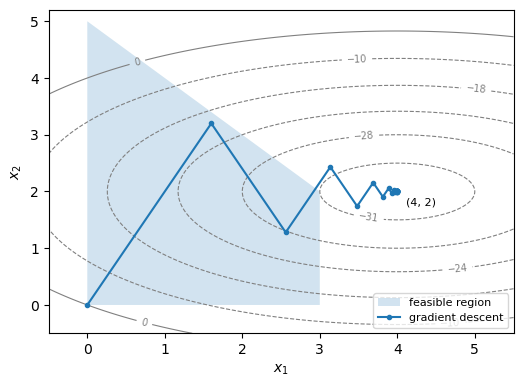

In [9]:
g1, g2 = np.meshgrid(np.linspace(-0.5, 5.5, 200), np.linspace(-0.5, 5.2, 200))
zz = g1**2 + 4 * g2**2 - 8 * g1 - 16 * g2
region = np.array([[0, 0], [3, 0], [3, 2], [0, 5]])
fig, ax = plt.subplots(figsize=(6, 4.2))
cs = ax.contour(g1, g2, zz, levels=[-31, -28, -24, -18, -10, 0], colors="0.5", linewidths=0.8)
ax.clabel(cs, fontsize=7)
ax.fill(region[:, 0], region[:, 1], alpha=0.2, label="feasible region")
ax.plot(gd_path[:, 0], gd_path[:, 1], "o-", markersize=3, label="gradient descent")
ax.annotate("(4, 2)", (4, 2), textcoords="offset points", xytext=(6, -10), fontsize=8)
ax.set(xlim=(-0.5, 5.5), ylim=(-0.5, 5.2), xlabel="$x_1$", ylabel="$x_2$")
ax.legend(loc="lower right", fontsize=8)
plt.show()
# alt: Elliptical contours of z centred on (4, 2); gradient descent starts at the origin, zig-zags up and down in x2 while moving steadily right in x1, and settles at (4, 2), which lies outside the shaded feasible region with corners (0,0), (3,0), (3,2) and (0,5).

Gradient descent found the bottom of the bowl. Check that point against the two constraints.

In [10]:
print("x1 + x2 =", round(x[0] + x[1], 4), "(limit 5) | x1 =", round(x[0], 4), "(limit 3)")

x1 + x2 = 6.0 (limit 5) | x1 = 4.0 (limit 3)


## An interior-point method, a few steps by hand

To respect the constraints, go back to standard form and solve the optimality (KKT) conditions
with Newton's method, as in [the LP lesson](/resources/lp-algorithms/). The only change from LP is that the stationarity
condition now has $Qx$ in it:

$$\begin{aligned} Qx + c - A^\top y - s &= 0 \\ Ax &= b \\ x_i s_i &= \mu,\quad x, s > 0 \end{aligned}$$

Each step aims at a smaller $\mu$ (the factor `sigma`) and moves 90% of the way to the boundary.
Start from a strictly positive point that satisfies $Ax = b$.

In [11]:
x = np.array([1.0, 1.0, 3.0, 2.0])
s = np.ones(4)
y = np.zeros(2)
print("start: A @ x - b =", A @ x - b, "| z =", 0.5 * x @ Q @ x + c @ x)

start: A @ x - b = [0. 0.] | z = -19.0


**Predict:** after ten steps, how close to a corner of the feasible region will $(x_1, x_2)$ be,
and which corner?

In [12]:
ip_path = [x[:2].copy()]
sigma = 0.2
for k in range(10):
    mu = x @ s / 4
    K = np.block([[-Q, A.T, np.eye(4)],
                  [A, np.zeros((2, 2)), np.zeros((2, 4))],
                  [np.diag(s), np.zeros((4, 2)), np.diag(x)]])
    rhs = np.concatenate([Q @ x + c - A.T @ y - s, b - A @ x, sigma * mu - x * s])
    d = np.linalg.solve(K, rhs)
    dx, dy, ds = d[:4], d[4:6], d[6:]
    shrink = [1.0] + [-v / dv for v, dv in zip(np.r_[x, s], np.r_[dx, ds]) if dv < 0]
    alpha = 0.9 * min(shrink)
    x, y, s = x + alpha * dx, y + alpha * dy, s + alpha * ds
    ip_path.append(x[:2].copy())
    print(f"step {k + 1:2d}: x1 = {x[0]:.4f}, x2 = {x[1]:.4f}, z = {0.5 * x @ Q @ x + c @ x:8.4f}, mean x*s = {x @ s / 4:.1e}")

step  1: x1 = 1.6290, x2 = 1.3454, z = -24.6640, mean x*s = 9.9e-01
step  2: x1 = 2.8280, x2 = 1.8174, z = -30.4930, mean x*s = 1.8e-01
step  3: x1 = 2.9743, x2 = 1.8948, z = -30.9037, mean x*s = 5.4e-02
step  4: x1 = 2.9949, x2 = 1.9342, z = -30.9725, mean x*s = 1.8e-02
step  5: x1 = 2.9980, x2 = 1.9606, z = -30.9898, mean x*s = 6.4e-03
step  6: x1 = 2.9993, x2 = 1.9763, z = -30.9963, mean x*s = 2.3e-03
step  7: x1 = 2.9997, x2 = 1.9859, z = -30.9987, mean x*s = 8.2e-04
step  8: x1 = 2.9999, x2 = 1.9915, z = -30.9995, mean x*s = 2.9e-04
step  9: x1 = 3.0000, x2 = 1.9950, z = -30.9998, mean x*s = 1.1e-04
step 10: x1 = 3.0000, x2 = 1.9970, z = -30.9999, mean x*s = 3.8e-05


The dual prices $y$ belong to the two constraints. Keep them for the end.

In [13]:
print("y =", np.round(y, 4))

y = [-0.0241 -1.9759]


Both paths on one picture.

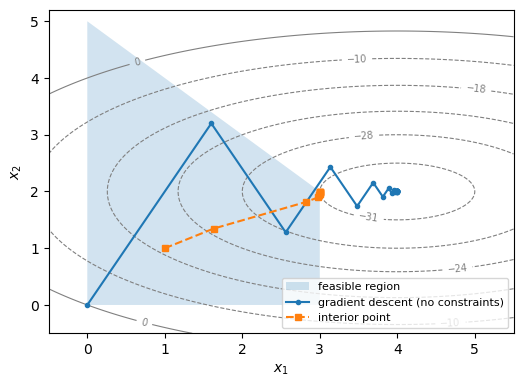

In [14]:
ip_path = np.array(ip_path)
fig, ax = plt.subplots(figsize=(6, 4.2))
cs = ax.contour(g1, g2, zz, levels=[-31, -28, -24, -18, -10, 0], colors="0.5", linewidths=0.8)
ax.clabel(cs, fontsize=7)
ax.fill(region[:, 0], region[:, 1], alpha=0.2, label="feasible region")
ax.plot(gd_path[:, 0], gd_path[:, 1], "o-", markersize=3, label="gradient descent (no constraints)")
ax.plot(ip_path[:, 0], ip_path[:, 1], "s--", markersize=4, label="interior point")
ax.set(xlim=(-0.5, 5.5), ylim=(-0.5, 5.2), xlabel="$x_1$", ylabel="$x_2$")
ax.legend(loc="lower right", fontsize=8)
plt.show()
# alt: Gradient descent zig-zags from the origin to (4, 2) outside the shaded region, while the interior-point path starts at (1, 1) inside the region and moves up and to the right into the corner (3, 2), where the z = -31 contour touches the region.

## Gurobi

The same QP in GurobiPy, written with the inequalities directly; Gurobi adds its own slacks. It is
solved twice, once by each of two algorithms. **Predict the objective value and the duals before
you run it.**

In [15]:
m = gp.Model("qp")
xv = m.addVars(2, name="x")
m.setObjective(xv[0] * xv[0] + 4 * xv[1] * xv[1] - 8 * xv[0] - 16 * xv[1], GRB.MINIMIZE)
m.addConstr(xv[0] + xv[1] <= 5, name="sum")
m.addConstr(xv[0] <= 3, name="x1cap")
m.Params.OutputFlag = 0
for method, name in [(2, "barrier"), (0, "primal simplex")]:
    m.reset()
    m.Params.Method = method
    m.optimize()
    duals = [round(con.Pi, 4) for con in m.getConstrs()]
    print(f"{name:14s} z = {m.ObjVal:.6f}  x = {[round(v.X, 6) for v in xv.values()]}  duals = {duals}")

Restricted license - for non-production use only - expires 2027-11-29


barrier        z = -31.000000  x = [3.0, 1.999923]  duals = [-0.0006, -1.9994]
primal simplex z = -31.000000  x = [3.0, 2.0]  duals = [0.0, -2.0]


Gurobi has both families for a QP too: `Method = 2` is its barrier (interior-point) method and
`Method = 0` is a simplex method adapted to QPs. Compare both rows with your interior-point steps and
with $y$.

- The constraint $x_1 + x_2 \le 5$ has no slack left, yet its dual is zero. Look at where the
  bowl's centre sits relative to that line: why does pushing it outward not help?
- Raise the cap on $x_1$ from 3 to 3.5. Predict the new $z$ from the dual, then re-solve. Why is
  the prediction no longer exact, as it was for an LP?
- Change the objective to $x_1^2 - 4x_2^2 - 8x_1 - 16x_2$. What do the eigenvalues of $Q$ say, and
  where does gradient descent go?